# SWYNEX Task 3 — Modeling and Evaluation
### Customer churn prediction on the IBM Telco dataset

**Author:** Karthik · **Programme:** SWYNEX Technologies Data Science Internship · **Builds on:** Task 1 (Data Preparation) and Task 2 (EDA) in this repository

## 1. Business problem and success criteria
A telecom operator loses revenue every time a customer leaves. Retention offers are costly, so they should go to customers who are *likely to churn* and *worth keeping*.

| Item | Decision |
|---|---|
| Task | Binary classification: will the customer churn? (`Churn = Yes`) |
| Primary metric | **PR-AUC (average precision)**: robust to class imbalance (~26% churners) |
| Secondary metrics | ROC-AUC, recall/precision at the chosen threshold, Brier score (probability quality) |
| Decision metric | **Expected net retention benefit** under explicit cost assumptions (section 8) |
| Baselines | Majority-class dummy, Logistic Regression |
| Validation | Stratified 80/20 train/test split; 5-fold stratified CV on train only; test set touched once |

**Approach:** baseline → stronger models → hyperparameter tuning → held-out evaluation with confidence intervals → calibration → business-driven threshold → interpretation → error analysis → limitations.

## 2. Setup

In [1]:
import warnings, json, joblib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, precision_score, recall_score,
                             f1_score, RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore")
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))          # make `src` importable
FIG, MODELS = ROOT / "reports" / "figures", ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / name, bbox_inches="tight")

## 3. Data
The notebook loads the **cleaned dataset from Task 1** (`data/processed/telco_churn_clean.csv`). If it is missing, the Task 1 pipeline (`src/data_prep.py`) is run first, so the notebook works from a fresh clone.

In [2]:
PROCESSED = ROOT / "data" / "processed" / "telco_churn_clean.csv"
if not PROCESSED.exists():
    from src import data_prep as dp
    dp.main([])                       # raw -> validated clean CSV (Task 1 pipeline)

df = pd.read_csv(PROCESSED).drop(columns=["customer_id"])
print(f"Source: Task 1 cleaned dataset | shape: {df.shape}")
df.head()

Source: Task 1 cleaned dataset | shape: (7043, 20)


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,Female,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,Male,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,Male,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,Male,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


### 3.1 Data quality and leakage checks

In [3]:
checks = pd.Series({
    "rows": len(df),
    "duplicate rows": int(df.duplicated().sum()),
    "missing values": int(df.isna().sum().sum()),
    "churn rate": round(df["churn"].mean(), 4),
})
print(checks.to_string())
print("\nColumns:", [c for c in df.columns if c != "churn"])

rows              7043.0000
duplicate rows      22.0000
missing values       0.0000
churn rate           0.2654

Columns: ['gender', 'senior_citizen', 'partner', 'dependents', 'tenure', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges']


**Leakage review.** Every feature is known *before* the churn event (demographics, subscribed services, contract, billing, tenure). There is no post-churn field such as cancellation date, exit survey or retention-call outcome, so no column is dropped for leakage. `TotalCharges` is a cumulative figure that scales with tenure; it is retained because it is available at prediction time.

**Duplicates.** The 22 rows that are identical once `customer_id` is dropped are retained: identical service/billing profiles are plausible for distinct customers, so they are not treated as errors.

## 4. Feature engineering and preprocessing
One stateless engineered feature: the **number of add-on services** (security, backup, protection, support, streaming). Stateless means it cannot leak information between train and test. All scaling and encoding sit inside a `Pipeline`, so they are fit on training folds only.

The function is defined in `src/features.py` (not in the notebook) so that the pickled model in `models/` can be loaded from any script.

In [4]:
from src.features import add_features   # lives in src/ so the saved model can be loaded anywhere

y = df["churn"]
X = df.drop(columns="churn")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

X_fe = add_features(X_train)
num_cols = X_fe.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_fe.columns if c not in num_cols]

def make_pre(scale=True):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("encode", ColumnTransformer([
            ("num", StandardScaler() if scale else "passthrough", num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])),
    ])

print(f"train={len(X_train)}  test={len(X_test)}  | churn rate train={y_train.mean():.3f}, test={y_test.mean():.3f}")
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical features")

train=5634  test=1409  | churn rate train=0.265, test=0.265
16 numeric + 4 categorical features


## 5. Baselines and candidate models (5-fold CV on the training set)
Four candidates are compared on identical folds. Metrics are reported as mean ± std across folds, so differences smaller than the fold-to-fold noise are not over-interpreted.

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
candidates = {
    "Dummy (majority)":    Pipeline([("pre", make_pre()), ("clf", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=2000))]),
    "Random Forest":       Pipeline([("pre", make_pre(False)), ("clf", RandomForestClassifier(
                               n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED))]),
    "Hist. Gradient Boosting": Pipeline([("pre", make_pre(False)), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
}
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "Brier": "neg_brier_score"}

def cv_table(models):
    rows = []
    for name, m in models.items():
        r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"model": name,
                     "PR-AUC": f"{r['test_PR-AUC'].mean():.3f} ± {r['test_PR-AUC'].std():.3f}",
                     "ROC-AUC": f"{r['test_ROC-AUC'].mean():.3f} ± {r['test_ROC-AUC'].std():.3f}",
                     "Brier": f"{-r['test_Brier'].mean():.3f}",
                     "_pr": r["test_PR-AUC"].mean()})
    return pd.DataFrame(rows).set_index("model")

baseline_cv = cv_table(candidates)
baseline_cv.drop(columns="_pr")

,PR-AUC,ROC-AUC,Brier
model,,,
Dummy (majority),0.265 ± 0.000,0.500 ± 0.000,0.195
Logistic Regression,0.661 ± 0.019,0.846 ± 0.012,0.135
Random Forest,0.656 ± 0.023,0.844 ± 0.010,0.136
Hist. Gradient Boosting,0.641 ± 0.023,0.834 ± 0.007,0.141


## 6. Hyperparameter tuning
Randomised search (optimising **PR-AUC**, inner 5-fold CV on the training set only) for the two most promising model families: regularised Logistic Regression and Gradient Boosting.

In [6]:
searches = {
    "Logistic Regression (tuned)": RandomizedSearchCV(
        Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=3000))]),
        {"clf__C": loguniform(1e-3, 1e2)}, n_iter=20, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1),
    "Gradient Boosting (tuned)": RandomizedSearchCV(
        Pipeline([("pre", make_pre(False)), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
        {"clf__learning_rate": [0.02, 0.04, 0.06, 0.1],
         "clf__max_iter": [100, 200, 300],
         "clf__max_depth": [2, 3, 4, None],
         "clf__max_leaf_nodes": [8, 15, 31],
         "clf__min_samples_leaf": [20, 40, 80],
         "clf__l2_regularization": [0, 0.1, 1, 10]},
        n_iter=30, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1),
}
for name, s in searches.items():
    s.fit(X_train, y_train)
    print(f"{name}: best CV PR-AUC = {s.best_score_:.3f}\n   {s.best_params_}")

tuned = {k: s.best_estimator_ for k, s in searches.items()}
tuned_cv = cv_table(tuned)
comparison = pd.concat([baseline_cv, tuned_cv])
comparison.drop(columns="_pr")

Logistic Regression (tuned): best CV PR-AUC = 0.662
   {'clf__C': np.float64(3.4702669886504163)}


Gradient Boosting (tuned): best CV PR-AUC = 0.667
   {'clf__min_samples_leaf': 80, 'clf__max_leaf_nodes': 8, 'clf__max_iter': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 10}


,PR-AUC,ROC-AUC,Brier
model,,,
Dummy (majority),0.265 ± 0.000,0.500 ± 0.000,0.195
Logistic Regression,0.661 ± 0.019,0.846 ± 0.012,0.135
Random Forest,0.656 ± 0.023,0.844 ± 0.010,0.136
Hist. Gradient Boosting,0.641 ± 0.023,0.834 ± 0.007,0.141
Logistic Regression (tuned),0.662 ± 0.019,0.846 ± 0.013,0.135
Gradient Boosting (tuned),0.667 ± 0.023,0.849 ± 0.012,0.134


**Reading the comparison.** Tuned Gradient Boosting has the highest CV PR-AUC (0.667), but its margin over Logistic Regression (0.662) is far smaller than the fold-to-fold standard deviation (~0.02), so the models are statistically close. Gradient Boosting is selected as it is nominally best and slightly better on ROC-AUC and Brier score; Logistic Regression remains a defensible, more transparent alternative if explainability is prioritised over a marginal gain.

In [7]:
best_name = comparison["_pr"].idxmax()
final_model = {**candidates, **tuned}[best_name]
print("Selected model:", best_name)
final_model.fit(X_train, y_train);

Selected model: Gradient Boosting (tuned)


## 7. Held-out test evaluation
The test set is used **once**, with the selected model. Uncertainty is quantified with a 500-sample bootstrap of the test set.

In [8]:
proba = final_model.predict_proba(X_test)[:, 1]

rng = np.random.default_rng(SEED)
boot = {"PR-AUC": [], "ROC-AUC": []}
for _ in range(500):
    idx = rng.integers(0, len(y_test), len(y_test))
    yt, pp = y_test.values[idx], proba[idx]
    boot["PR-AUC"].append(average_precision_score(yt, pp)); boot["ROC-AUC"].append(roc_auc_score(yt, pp))

test_metrics = {
    "PR-AUC": average_precision_score(y_test, proba), "ROC-AUC": roc_auc_score(y_test, proba),
    "Brier": brier_score_loss(y_test, proba),
}
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}
base_rate = y_test.mean()
pd.DataFrame({
    "test value": {k: round(v, 3) for k, v in test_metrics.items()},
    "95% CI": {"PR-AUC": f"{ci['PR-AUC'][0]:.3f} – {ci['PR-AUC'][1]:.3f}",
               "ROC-AUC": f"{ci['ROC-AUC'][0]:.3f} – {ci['ROC-AUC'][1]:.3f}", "Brier": "–"},
    "no-skill reference": {"PR-AUC": round(base_rate, 3), "ROC-AUC": 0.5, "Brier": round(base_rate * (1 - base_rate), 3)},
})

,test value,95% CI,no-skill reference
PR-AUC,0.662,0.609 – 0.713,0.265
ROC-AUC,0.846,0.823 – 0.868,0.500
Brier,0.136,–,0.195


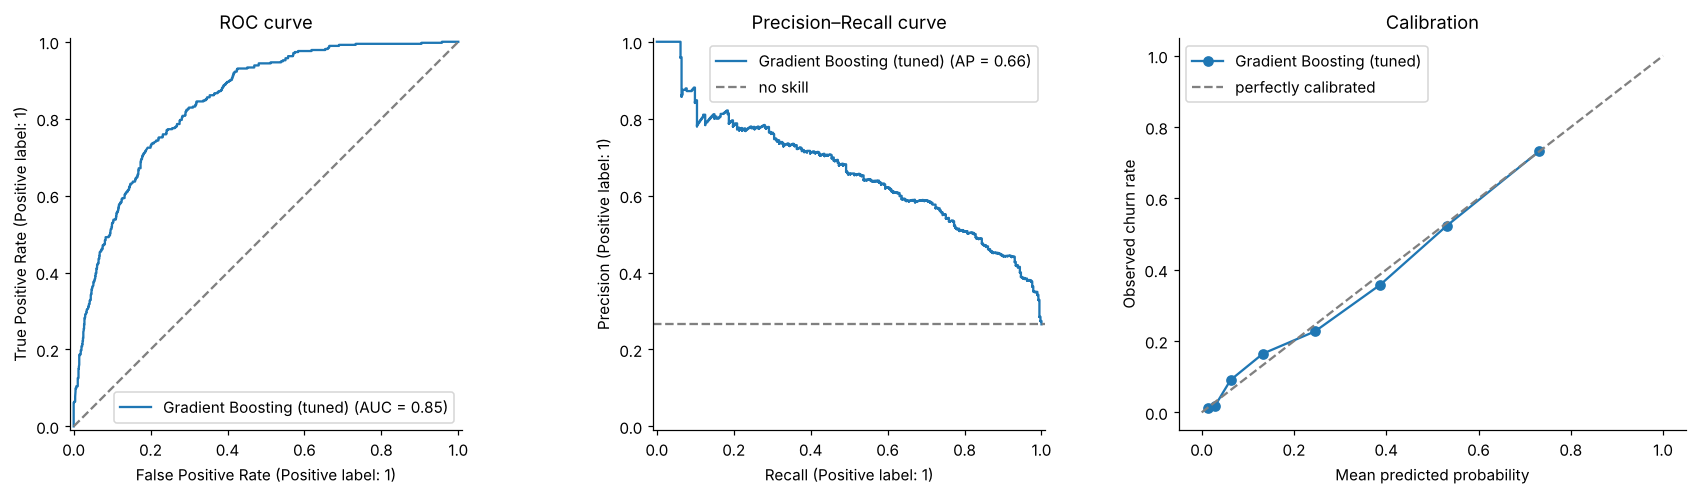

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[0], name=best_name); ax[0].plot([0, 1], [0, 1], "--", c="grey"); ax[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[1], name=best_name); ax[1].axhline(base_rate, ls="--", c="grey", label="no skill"); ax[1].legend(); ax[1].set_title("Precision–Recall curve")
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=8, strategy="quantile")
ax[2].plot(mean_pred, frac_pos, "o-", label=best_name); ax[2].plot([0, 1], [0, 1], "--", c="grey", label="perfectly calibrated")
ax[2].set_xlabel("Mean predicted probability"); ax[2].set_ylabel("Observed churn rate"); ax[2].set_title("Calibration"); ax[2].legend()
plt.tight_layout(); savefig("model_01_roc_pr_calibration.png"); plt.show()

## 8. Choosing the decision threshold from business cost
A default 0.5 cut-off ignores that a missed churner and a wasted offer have different costs. The threshold is chosen on **out-of-fold predictions from the training set**, never on the test set, and then applied to the test set.

**Assumptions (illustrative, to be replaced with SWYNEX/client figures):**
- A retention offer costs **$50** per contacted customer.
- An offer saves **30%** of true churners.
- A saved customer is worth **12 months of their `MonthlyCharges`**.

Net benefit = Σ over contacted customers [ 𝟙(churner) × 0.30 × 12 × MonthlyCharges − $50 ]

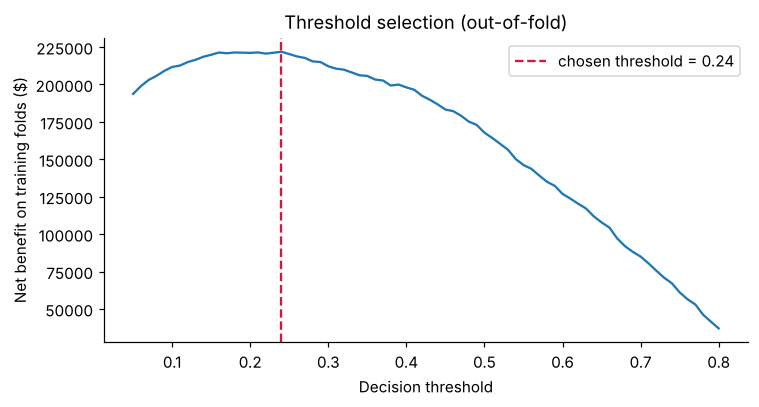

Chosen threshold: 0.24


In [10]:
OFFER_COST, SAVE_RATE, HORIZON_MONTHS = 50.0, 0.30, 12

def net_benefit(y_true, p, monthly, t):
    contact = p >= t
    return float((contact * (y_true * SAVE_RATE * HORIZON_MONTHS * monthly - OFFER_COST)).sum())

oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
grid = np.linspace(0.05, 0.8, 76)
oof_nb = [net_benefit(y_train.values, oof, X_train["monthly_charges"].values, t) for t in grid]
THRESH = float(grid[int(np.argmax(oof_nb))])

plt.figure(figsize=(7, 3.8))
plt.plot(grid, oof_nb); plt.axvline(THRESH, c="crimson", ls="--", label=f"chosen threshold = {THRESH:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Net benefit on training folds ($)"); plt.title("Threshold selection (out-of-fold)")
plt.legend(); plt.tight_layout(); savefig("model_02_threshold_selection.png"); plt.show()
print(f"Chosen threshold: {THRESH:.2f}")

,precision,recall,F1,customers contacted,net benefit ($)
Default threshold 0.5,0.656,0.524,0.582,299,39340.52
Cost-optimised (0.24),0.500,0.826,0.623,618,51738.18


Reference: contacting every customer = $27,524; contacting nobody = $0


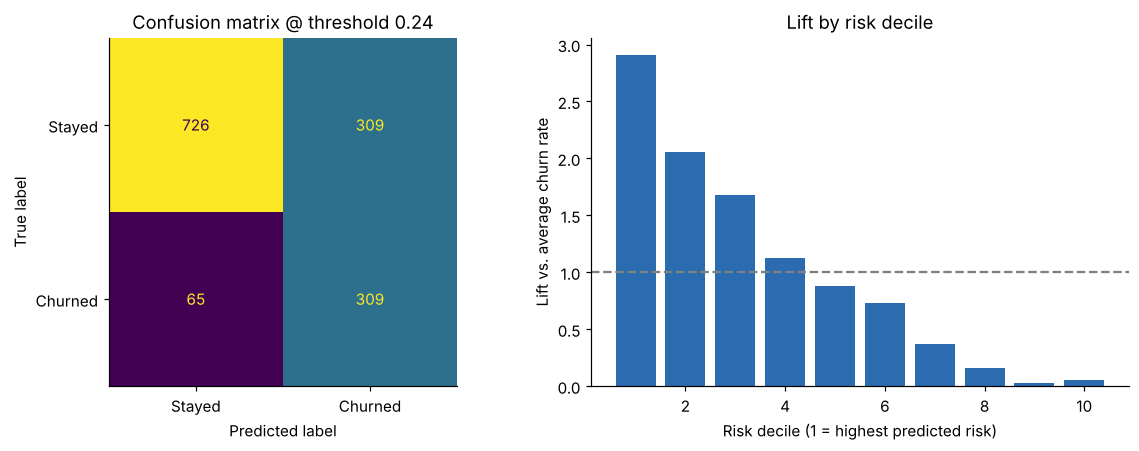

In [11]:
pred = (proba >= THRESH).astype(int)
pred_default = (proba >= 0.5).astype(int)
mon = X_test["monthly_charges"].values

summary = pd.DataFrame({
    "precision": [precision_score(y_test, pred_default), precision_score(y_test, pred)],
    "recall":    [recall_score(y_test, pred_default),    recall_score(y_test, pred)],
    "F1":        [f1_score(y_test, pred_default),        f1_score(y_test, pred)],
    "customers contacted": [pred_default.sum(), pred.sum()],
    "net benefit ($)": [net_benefit(y_test.values, proba, mon, 0.5), net_benefit(y_test.values, proba, mon, THRESH)],
}, index=["Default threshold 0.5", f"Cost-optimised ({THRESH:.2f})"]).round(3)
contact_all = float((y_test.values * SAVE_RATE * HORIZON_MONTHS * mon - OFFER_COST).sum())
display(summary)
print(f"Reference: contacting every customer = ${contact_all:,.0f}; contacting nobody = $0")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f"Confusion matrix @ threshold {THRESH:.2f}")
dec = pd.DataFrame({"y": y_test.values, "p": proba}).sort_values("p", ascending=False).reset_index(drop=True)
dec["decile"] = pd.qcut(dec.index, 10, labels=range(1, 11))
lift = dec.groupby("decile", observed=True)["y"].mean() / base_rate
ax[1].bar(lift.index.astype(int), lift.values, color="#2b6cb0"); ax[1].axhline(1, c="grey", ls="--")
ax[1].set_xlabel("Risk decile (1 = highest predicted risk)"); ax[1].set_ylabel("Lift vs. average churn rate"); ax[1].set_title("Lift by risk decile")
plt.tight_layout(); savefig("model_03_confusion_and_lift.png"); plt.show()

## 9. Interpretation
Permutation importance is computed on the **test set at original-feature level** (the full pipeline is shuffled, so one-hot columns are not split apart). It measures how much PR-AUC drops when a feature is scrambled.

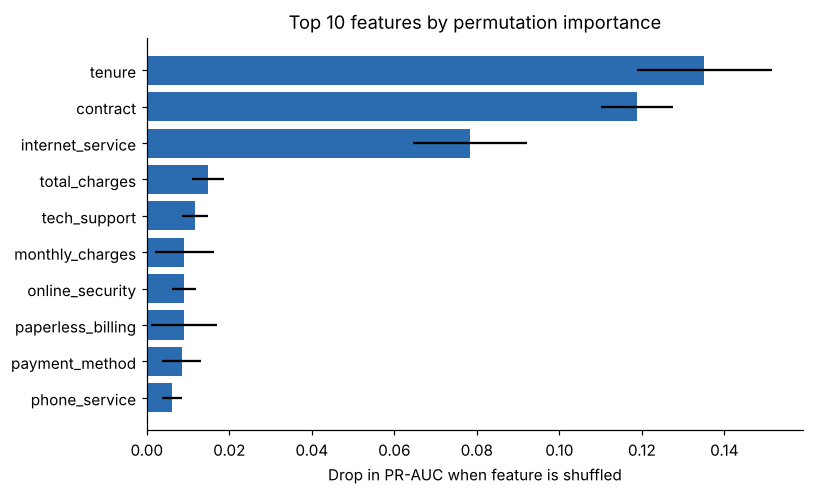

Top 3 drivers: ['tenure', 'contract', 'internet_service']


In [12]:
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision", n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns).sort_values("mean")
top = imp.tail(10)
plt.figure(figsize=(7.5, 4.6))
plt.barh(top.index, top["mean"], xerr=top["std"], color="#2b6cb0")
plt.xlabel("Drop in PR-AUC when feature is shuffled"); plt.title("Top 10 features by permutation importance")
plt.tight_layout(); savefig("model_04_permutation_importance.png"); plt.show()
top_features = list(imp.sort_values("mean", ascending=False).head(3).index)
print("Top 3 drivers:", top_features)

## 10. Error analysis by customer segment
Aggregate metrics can hide uneven performance. Recall and precision are checked across contract type and tenure bands.

In [13]:
seg = X_test.copy(); seg["y"] = y_test.values; seg["pred"] = pred
seg["tenure band"] = pd.cut(seg["tenure"], [-1, 12, 24, 48, 100], labels=["0–12m", "13–24m", "25–48m", "49m+"])
def seg_table(col):
    g = seg.groupby(col, observed=True)
    return pd.DataFrame({"customers": g.size(), "actual churn rate": g["y"].mean(),
                         "recall": g.apply(lambda d: recall_score(d["y"], d["pred"]) if d["y"].sum() else np.nan),
                         "precision": g.apply(lambda d: precision_score(d["y"], d["pred"]) if d["pred"].sum() else np.nan)}).round(3)
display(seg_table("contract")); display(seg_table("tenure band"))

,customers,actual churn rate,recall,precision
contract,,,,
Month-to-month,773,0.426,0.918,0.514
One year,300,0.120,0.194,0.226
Two year,336,0.027,0.000,NaN


,customers,actual churn rate,recall,precision
tenure band,,,,
0–12m,449,0.479,0.907,0.577
13–24m,206,0.291,0.900,0.450
25–48m,304,0.211,0.703,0.429
49m+,450,0.078,0.429,0.273


## 11. Save model artefacts

In [14]:
joblib.dump(final_model, MODELS / "churn_model.joblib")
metrics = {"selected_model": best_name, "threshold": THRESH,
           "test": {k: round(float(v), 4) for k, v in test_metrics.items()},
           "test_95ci": {k: [round(float(x), 4) for x in v] for k, v in ci.items()},
           "cost_assumptions": {"offer_cost": OFFER_COST, "save_rate": SAVE_RATE, "horizon_months": HORIZON_MONTHS},
           "sklearn_seed": SEED}
(MODELS / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))

{
  "selected_model": "Gradient Boosting (tuned)",
  "threshold": 0.24,
  "test": {
    "PR-AUC": 0.6618,
    "ROC-AUC": 0.8458,
    "Brier": 0.1357
  },
  "test_95ci": {
    "PR-AUC": [
      0.6085,
      0.7134
    ],
    "ROC-AUC": [
      0.8231,
      0.8678
    ]
  },
  "cost_assumptions": {
    "offer_cost": 50.0,
    "save_rate": 0.3,
    "horizon_months": 12
  },
  "sklearn_seed": 42
}


## 12. Executive summary (auto-generated from the results above)

In [15]:
nb_opt = summary.iloc[1]["net benefit ($)"]; nb_def = summary.iloc[0]["net benefit ($)"]
top_decile_capture = dec.iloc[: len(dec)//10]["y"].sum() / dec["y"].sum()
display(Markdown(f'''
- **Selected model:** {best_name}, chosen on cross-validated PR-AUC from {len(comparison)} candidates.
- **Test performance:** PR-AUC **{test_metrics["PR-AUC"]:.3f}** (95% CI {ci["PR-AUC"][0]:.3f}–{ci["PR-AUC"][1]:.3f}) against a no-skill level of {base_rate:.3f}; ROC-AUC **{test_metrics["ROC-AUC"]:.3f}** (95% CI {ci["ROC-AUC"][0]:.3f}–{ci["ROC-AUC"][1]:.3f}).
- **Targeting power:** the top 10% of customers by predicted risk contain **{top_decile_capture:.0%}** of all churners (lift {lift.iloc[0]:.1f}×).
- **Operating point:** threshold **{THRESH:.2f}** gives recall {summary.iloc[1]["recall"]:.2f} and precision {summary.iloc[1]["precision"]:.2f}; under the stated cost assumptions net benefit is **${nb_opt:,.0f}** vs ${nb_def:,.0f} at the default 0.5 threshold, on {len(y_test)} test customers.
- **Main drivers (permutation importance):** {", ".join(top_features)}.
'''))


- **Selected model:** Gradient Boosting (tuned), chosen on cross-validated PR-AUC from 6 candidates.
- **Test performance:** PR-AUC **0.662** (95% CI 0.609–0.713) against a no-skill level of 0.265; ROC-AUC **0.846** (95% CI 0.823–0.868).
- **Targeting power:** the top 10% of customers by predicted risk contain **29%** of all churners (lift 2.9×).
- **Operating point:** threshold **0.24** gives recall 0.83 and precision 0.50; under the stated cost assumptions net benefit is **$51,738** vs $39,341 at the default 0.5 threshold, on 1409 test customers.
- **Main drivers (permutation importance):** tenure, contract, internet_service.


## 13. Limitations
1. **Cost assumptions are illustrative.** The offer cost, save rate and 12-month value are placeholders; the optimal threshold and the dollar benefit move with them. They must be replaced with client figures before any deployment decision.
2. **Static snapshot, no time dimension.** The data cannot show *when* churn happens, so the model cannot be back-tested in time or monitored for drift, and a random split may be optimistic compared with a temporal split in production.
3. **Association, not causation.** Importance scores show which features the model relies on, not that changing them will reduce churn. Acting on drivers (e.g., contract upgrades) needs an A/B test.
4. **Single dataset and single split.** One public, single-operator dataset; performance may not transfer to other regions or customer bases. The bootstrap interval reflects test-set sampling noise only.
5. **Limited feature set.** There is no usage, complaint, network-quality or competitor-offer data, which are typically strong churn signals.
6. **Fairness not assessed.** Features such as `gender` and `senior_citizen` are present; a production system would need a fairness review and a decision on whether to exclude them.
7. **Modest tuning budget.** Randomised search with 20–30 iterations; the gains from further tuning are likely small relative to fold-to-fold variance.

## 14. Recommended next steps
- Replace cost assumptions with business figures and re-select the threshold.
- Add behavioural features (usage trends, support contacts) and validate on a time-based split.
- Compare against LightGBM/XGBoost and add SHAP explanations for per-customer reasons.
- Pilot with a randomised holdout group to measure true retention uplift, and monitor calibration and drift after launch.